# Resultados do Modelo — Predição de Alfabetização (Fase 3)

Carrega o modelo e as métricas já produzidos por
`python -m src.modeling.treinar` (não re-treina aqui: em ~1,85M alunos o
treino completo — 2 modelos + validação cruzada 5-fold + SHAP — leva
~33 minutos; rodar isso a cada abertura do notebook tornaria a revisão
impraticável). Este notebook é sobre **interpretar** o resultado, não
reproduzi-lo do zero — para reproduzir, ver "Como Reproduzir" no README.

In [1]:
import json
import sys
from pathlib import Path

import joblib
import pandas as pd
from IPython.display import Image, display

sys.path.insert(0, str(Path.cwd().parent))

ROOT = Path.cwd().parent
with open(ROOT / "reports" / "metricas_modelo.json", encoding="utf-8") as f:
    relatorio = json.load(f)

print(f"Modelo escolhido: {relatorio['modelo_escolhido']}")
print(f"Critério: {relatorio['criterio_escolha']}")
print(f"Treino: {relatorio['n_treino']:,} | Validação: {relatorio['n_validacao']:,} | Teste: {relatorio['n_teste']:,}")
print(f"Tempo total de treino: {relatorio['tempo_total_segundos']/60:.1f} min")

Modelo escolhido: random_forest
Critério: maior ROC-AUC no conjunto de validação
Treino: 1,296,296 | Validação: 277,778 | Teste: 277,778
Tempo total de treino: 32.8 min


## 1. Comparação entre os modelos candidatos (validação)

In [2]:
comparacao = []
for nome, resultado in relatorio["resultados_validacao_por_modelo"].items():
    linha = {"modelo": nome, **resultado["metricas_validacao"]}
    linha["cv_roc_auc_medio"] = resultado["validacao_cruzada"]["roc_auc_medio"]
    linha["cv_roc_auc_desvio"] = resultado["validacao_cruzada"]["roc_auc_desvio_padrao"]
    del linha["matriz_confusao"]
    comparacao.append(linha)

pd.DataFrame(comparacao).set_index("modelo")

,acuracia,precisao,recall,f1,roc_auc,cv_roc_auc_medio,cv_roc_auc_desvio
modelo,,,,,,,
regressao_logistica,0.5976,0.7102,0.5523,0.6214,0.6578,0.6587,0.0009
random_forest,0.6166,0.7134,0.5996,0.6516,0.6696,0.6704,0.0008


Random Forest supera a Regressão Logística em todas as métricas, mas por
margem modesta (~0,01-0,02 de ROC-AUC) — as features disponíveis têm
relação majoritariamente simples/linear com o alvo, um modelo não-linear
ganha pouco. O desvio padrão baixo entre os folds da validação cruzada
(<0,001 nos dois modelos) é o dado mais importante aqui: confirma que o
resultado é **estável**, não uma coincidência de um split específico —
exatamente o que a Fase 3 pede em "validação garantindo replicabilidade".

## 2. Desempenho no conjunto de teste (hold-out nunca visto)

In [3]:
teste = relatorio["metricas_teste_holdout"]
for k, v in teste.items():
    if k != "matriz_confusao":
        print(f"{k:12s}: {v}")

import numpy as np
mc = np.array(teste["matriz_confusao"])
print(f"\nMatriz de confusão:\n{mc}")
print(f"\nROC-AUC teste ({teste['roc_auc']}) vs. validação ({relatorio['resultados_validacao_por_modelo'][relatorio['modelo_escolhido']]['metricas_validacao']['roc_auc']}) — diferença mínima confirma que não houve overfit no critério de escolha do modelo.")

acuracia    : 0.6168
precisao    : 0.7135
recall      : 0.6001
f1          : 0.6519
roc_auc     : 0.6709

Matriz de confusão:
[[71685 40025]
 [66407 99661]]

ROC-AUC teste (0.6709) vs. validação (0.6696) — diferença mínima confirma que não houve overfit no critério de escolha do modelo.


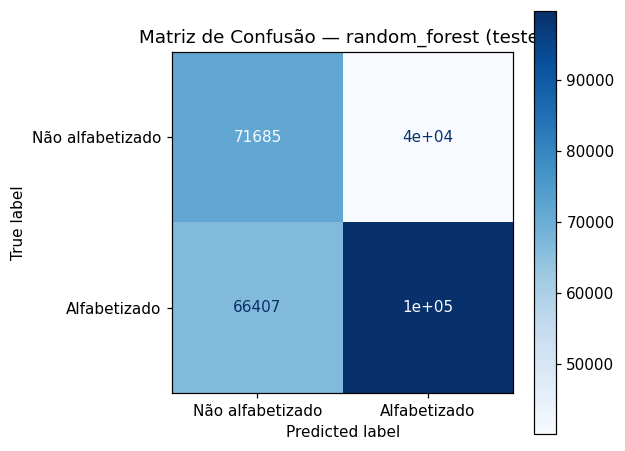

In [4]:
display(Image(filename=str(ROOT / "reports" / "figures" / "04_matriz_confusao.png")))

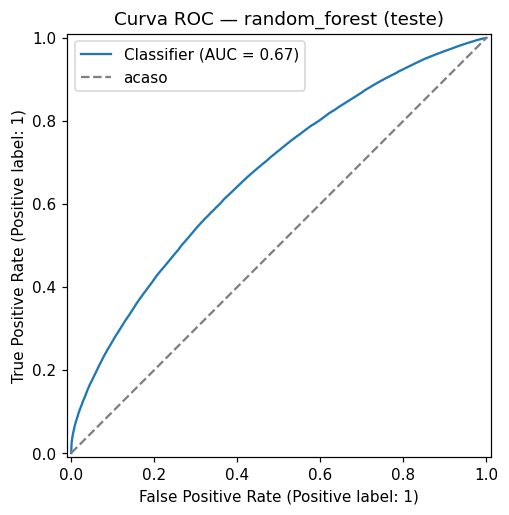

In [5]:
display(Image(filename=str(ROOT / "reports" / "figures" / "05_curva_roc.png")))

## 3. Interpretabilidade — o que o modelo aprendeu

Duas técnicas, propositalmente redundantes: `feature_importances_` (MDI,
nativo do Random Forest, mede o quanto cada variável reduz impureza nas
árvores) e SHAP (model-agnostic, mede a contribuição marginal de cada
variável por predição individual). Quando os dois concordam no ranking,
a conclusão fica mais robusta — não é um artefato de um método só.

In [6]:
fi = pd.read_csv(ROOT / "reports" / "feature_importance.csv")
shap_imp = pd.read_csv(ROOT / "reports" / "shap_importance.csv")

comparacao_rank = fi[["feature"]].head(10).reset_index().rename(columns={"index": "rank_mdi"})
comparacao_rank["rank_shap"] = comparacao_rank["feature"].map(
    {f: i for i, f in enumerate(shap_imp["feature"])}
)
comparacao_rank

,rank_mdi,feature,rank_shap
0,0,num__gap_indicador_nacional,0
1,1,num__taxa_alfabetizacao,1
2,2,cat__faixa_risco_Crítico,2
3,3,cat__faixa_risco_Adequado,6
4,4,cat__sigla_uf_RS,4
5,5,cat__sigla_uf_MG,3
6,6,cat__faixa_risco_Meta próxima/atingida,13
7,7,cat__sigla_uf_BA,7
8,8,cat__sigla_uf_CE,11
9,9,cat__faixa_risco_Atenção,12


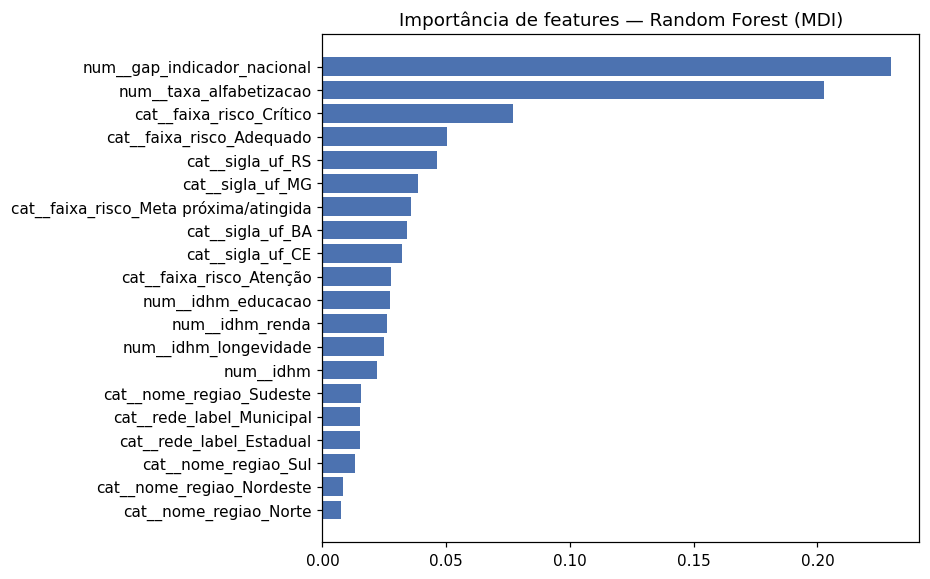

In [7]:
display(Image(filename=str(ROOT / "reports" / "figures" / "06_feature_importance.png")))

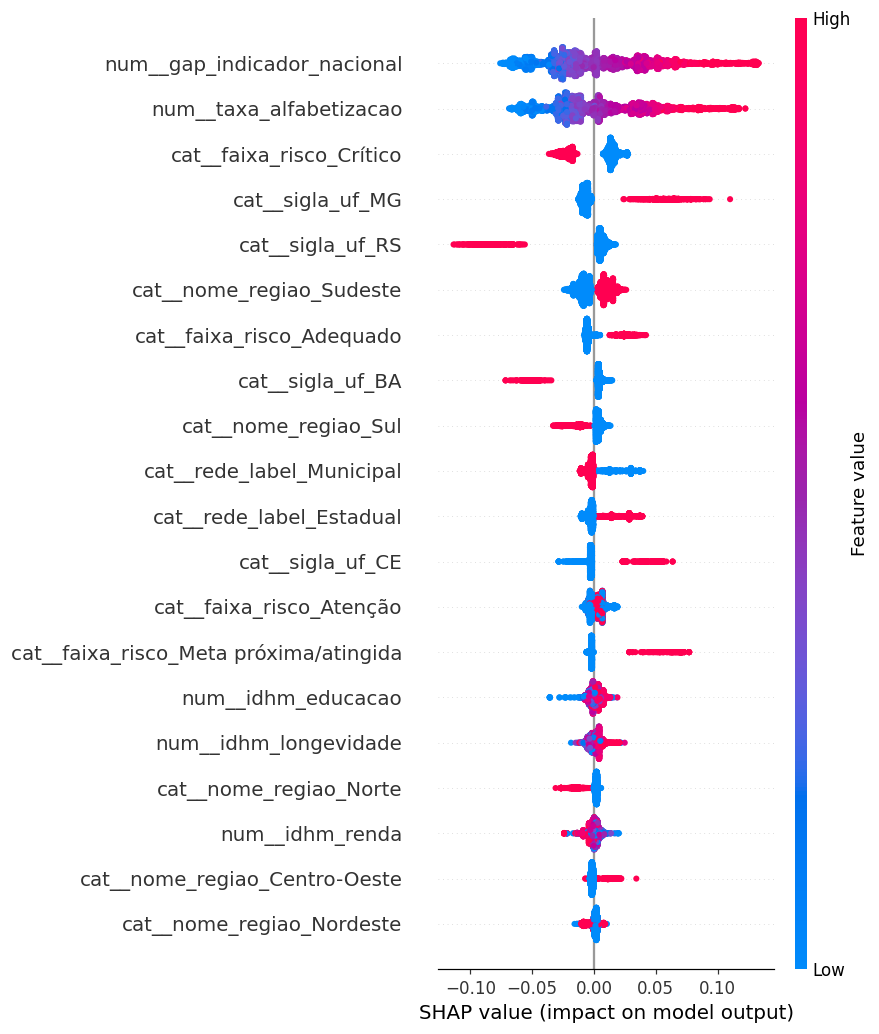

In [8]:
display(Image(filename=str(ROOT / "reports" / "figures" / "07_shap_summary.png")))

**Os dois métodos concordam no topo do ranking**: `gap_indicador_nacional`
e `taxa_alfabetizacao` (ambos o contexto municipal do ano anterior)
dominam a predição, seguidos por `faixa_risco_Crítico` — um município
historicamente crítico empurra a predição para "não alfabetizado" mais
do que qualquer variável de IDHM isolada.

**Insight para política pública**: o indicador histórico municipal prediz
melhor o resultado individual do que o desenvolvimento humano (IDHM)
puro. Isso sugere que políticas que miram diretamente a prática
pedagógica/gestão educacional municipal (o que o indicador reflete) têm
mais chance de impacto no curto prazo do que esperar o IDHM subir — que é
um indicador estrutural, lento de mover.

## 4. Limitações explícitas deste modelo

- **ROC-AUC ~0,67 é modesto, e isso é esperado, não um bug**: removemos
  deliberadamente `proficiencia` (vazamento perfeito — é a própria
  definição do alvo) e não há, nestes dados, nenhuma característica
  *individual* do aluno (desempenho anterior, características
  socioeconômicas da família, frequência escolar histórica) — só contexto
  territorial. Um modelo que previsse bem demais com essas features seria
  motivo de desconfiança, não de comemoração.
- **Amostra de rede Privada é pequena** (poucas dezenas de alunos nesta
  base, majoritariamente pública) — conclusões sobre essa rede não são
  confiáveis.
- **Só 2024 entra no treino/teste** (ver `src/preprocessing/dataset.py`,
  decisão 6) — 2023 não tem "ano anterior" disponível. Com mais anos de
  dados, a defasagem poderia ser testada em múltiplos anos (validação
  temporal real, não só um split aleatório dentro de um ano).
- **Split aleatório por aluno, não por município/escola** — alunos da
  mesma escola compartilham características não capturadas aqui; um
  `GroupKFold` por escola testaria generalização geográfica de forma mais
  rigorosa. Fica como evolução futura (ver README).